# Single-input linear regression model

for designing a Linear regression model with one x input, and y output, we will be using two different paths for our model.

A: Direct Implementation

B: Scikit-learn implementation

firstly, we'll add the necessary libraries to work with:


In [4]:
import numpy as np, matplotlib.pyplot as plt, pandas as pd

# Part 1, the formula


there are several formulas that needs to be included to design a simple regression model, the first one is:

f_wb(x) = y = wx + b 

this is the mainstream formula for linear regression, which is the model itself, but for us to know the accuracy, and optimization, we need to also understand our loss,

the loss formula consists of two formulas which are used for different purposes

the easier/weaker formula is:

[LATEX]

L\left(w,\ b\right)\ =\ \sum_{n=1}^{m}\ \left(\left|y^{\left(i\right)}\ -\ f_{w,b}\left(x\right)^{\left(i\right)}\right|\right)

[NON-LATEX]

l(w, b) = sum( |y^(i)-f_wb(x)^(i)| )

this formula is alright, and it will be implemented and shown for you. but it is not the best and most accurate, thus, isn't used as much in the industry


the next formula is the better version, which instead of a v shape, it will draw a bowl


[LATEX]

L\left(w,\ b\right)\ =\ \ \frac{1}{2m}\sum_{n=1}^{m}\left(y\left(i\right)\ -\ f_{w,\ b}\left(x\right)^{\left(i\right)}\right)^{2\ }

[NON-LATEX]

l(w, b) = 1/2m * sum*[ (y^(i) - f_wb(x)^(i))^2 ]

this formula shapes a bowl, which will treat less accurate models more harshly




here we will draw both models in 2D, (remember, these models are in 3D, but this will be an estimation of their shape in 2D)

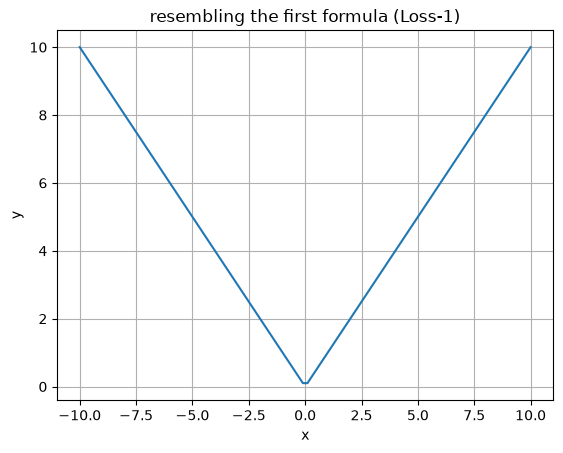

In [5]:
x_showcase1 = np.linspace(-10, 10, 100)
y_showcase1 = np.abs(x_showcase1)

plt.plot(x_showcase1, y_showcase1)
plt.xlabel("x")
plt.ylabel("y")
plt.title("resembling the first formula (Loss-1)")
plt.grid(True)
plt.show()

# P1-B, Loss-2

Now let's see the L2 formula:

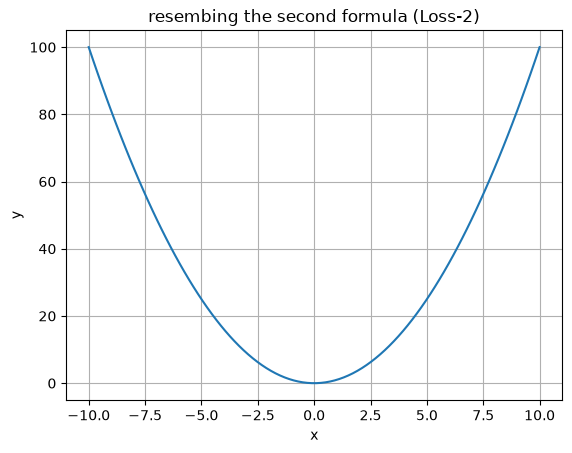

In [6]:
x_showcase2 = np.linspace(-10, 10, 100)
y_showcase2 = x_showcase2**2
plt.plot(x_showcase2, y_showcase2)
plt.xlabel("x")
plt.ylabel("y")
plt.title("resembing the second formula (Loss-2)")
plt.grid(True)
plt.show()

# gradient descent formula

Now that we have seen the loss formulas and a representation of how they would look like, its time to introduce the gradient descent



what is gradient descent? its an algorithm that is used to lower the amount of the loss, which it does so by taking small steps down the mountain of the 3D loss formula

to introduce it in code, we need to make sure that we update both the w and b variables at the same time, showing it to you will be easier than explaining it:
[LATEX]

new\ w\ =\ w\ -\ a\ \cdot\frac{∂L}{∂w}
new\ b\ =\ b\ -\ a\cdot\frac{∂L}{∂b}

w\ =\ new\ w\
b\ =\ new\ b\

[NON-LATEX]

new_w = w - a*(partial_derivative_of_l_over_w)
new_b = b - a*(partial_derivative_of_l_over_b)

w = new_w
b = new_b

as you see, we first calculate the gradient descent for both w & b, after doing so we shall give the new values back to w & b,
if we first give the new w to w, b will be off-set and the answer will be thrown off of the correct algorithm formula

the partial derivative of l over w & b is the formulas below:

[LATEX]

\frac{∂L}{∂w}=\frac{1}{m}\sum_{n=1}^{m}\left[\left(f_{w,b}\left(x^{\left(i\right)}\right)\ -\ y^{\left(i\right)}\right)x^{\left(i\right)}\right]

\frac{∂L}{∂b}\ =\ \frac{1}{m}\sum_{n=1}^{m}\left(f_{w,b}\left(x^{\left(i\right)}\right)\ -\ y^{\left(i\right)}\right)

[NON-LATEX]

partial derivative = pd

pd_L/pd_w = 1/m * sum( x^(i)*( f_wb(x^(i)) - y^(i) ) )
pd_L/pd_b = 1/m *sum(f_wb(x^(i)) - y^(i))

Let's implement the gradient descent with a simple dataset with one x:

In [7]:
# we'll load a test dataset with meters as input and the price as output price( 1 = 1'000$)
# the dataset is not accurate and is only a representation, be aware

# take a look at our dataset, we'll use pandas to gain access to our dataset
df = pd.read_csv("dataset.csv")
print(df)

   meters  price
0      80    100
1     100    130
2     120    160
3      60     50
4      70     55
5     120    163
6     150    190
7     200    270
8     100    144
9      90     90


In [43]:
#here we will give both of our features and targets variables 

x_train = df.meters
y_train = df.price

# we will also declare w & b values

w = 1
b = 1

print(f"x: \n{x_train} \n\ny: \n{y_train}")

x: 
0     80
1    100
2    120
3     60
4     70
5    120
6    150
7    200
8    100
9     90
Name: meters, dtype: int64 

y: 
0    100
1    130
2    160
3     50
4     55
5    163
6    190
7    270
8    144
9     90
Name: price, dtype: int64


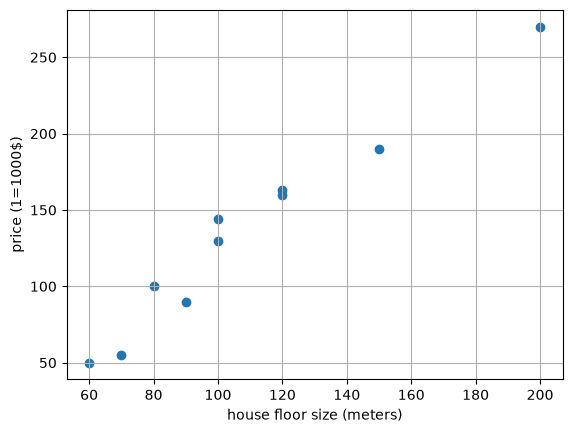

In [44]:
# lets draw these numbers using matplotlib

plt.scatter(x_train, y_train)
plt.xlabel("house floor size (meters)")
plt.ylabel("price (1=1000$)")
plt.grid(True)
plt.show()

in actual model training, our dataset would be enormous, this here is a very basic and simple dataset for representation 

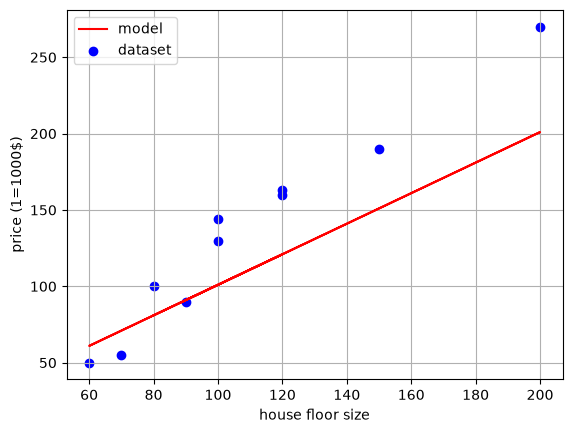

In [45]:
# simple model with our dataset in place, comparing the prediction to our targets
def model(x, w, b):
    m = len(x)
    f_wb = np.zeros(m)
    for i in range(m):
        f_wb[i] = w*x[i]+b
    return f_wb

f_wb = model(x_train, w, b)

plt.plot(x_train, f_wb, c="r", label="model")
plt.scatter(x_train, y_train, c="b", label="dataset")
plt.xlabel("house floor size")
plt.ylabel("price (1=1000$)")
plt.legend()
plt.grid(True)
plt.show()

# comparing the model with our data

Now, as you can see, our model isn't horrible, but you clearly can see that it is way off some points, and accurate with others, which is not helpful at all, so lets fix that


we will now calculate the loss, lets see how far are we from the truth, shall we?

In [11]:
# loss formula

def loss(y, x, y_hat):
    m = len(x)
    # we'll now add (y(i) - y_hat(i))**2
    #p_1 (part_1)
    p_1 = np.zeros(m)
    for i in range(m):
        p_1[i] = (y[i] - y_hat[i])**2
    return sum(p_1)*(1/2*m)
loss_cost = loss(y_train, x_train, f_wb)
print(loss_cost)



46350.0


As you can see, the amount of our loss was estimated to be very big, considering that you haven't touched the w & b.

(IMPORTANT: the way that we used to estimate the loss is very inefficent, with vectorization, it will be very easier, but that will not be covered in this lesson)

Alright, it's time to fix our loss, and for that, lets calculate the gradient descent



In [46]:
# reinitializing our values for easier access:
w = 1
b = 1
a = 0.0001


def partial_derivative(x, y, w, b):
    # this function will only calculate the partial derivative, the next function
    # will calculate the gradient descent
    m = len(x)
    partial_derivative_W_pt1 = np.zeros(m)
    partial_derivative_B_pt1 = np.zeros(m)
    for i in range(m):
        f_wb = model(x, w, b)
        partial_derivative_W_pt1[i] = (f_wb[i]-y[i])*x[i]
        partial_derivative_B_pt1[i] = (f_wb[i]-y[i])
    pd_w = sum(partial_derivative_W_pt1) * 1/m
    pd_b = sum(partial_derivative_B_pt1) * 1/m
    return pd_w, pd_b

def gradient_descent(x,y,w,b,a):

    old_model = model(x, w, b)
    old_loss = loss(y, x, old_model)
    print(f"old loss: {old_loss} \n calculating gradient descent...")
    loop = True
    for i in range(1000000):
        pd_w, pd_b = partial_derivative(x,y,w,b)
        w = w - a*pd_w
        b = b - a*pd_b
        inwork_model = model(x, w, b)
        inwork_loss = loss(y, x, inwork_model)
        if inwork_loss <= 1000:
            break
        
    new_model = model(x, w, b)
    new_loss =  loss(y, x, new_model)
    print(f"\n\n new loss: {new_loss}\n calculation finished, w & b values:")
    print(f" w: {w}\n b: {b}")
    # also return the new values
    return w, b

In [47]:
# now, we will run the gradient descent:
# IMPORTANT: this proccess took 2 minutes on my system, please note that it 
# could take more or less time than this number

# the old loss will be a very large number, and the new loss would be around 
# 8500,do not worry, in some times the loss can be high but the accuracy is on point
gradient_descent(x_train, y_train, w, b, a)

old loss: 64980.0 
 calculating gradient descent...


 new loss: 8503.176243470536
 calculation finished, w & b values:
 w: 1.5650067895490758
 b: -35.385698935576805


(np.float64(1.5650067895490758), np.float64(-35.385698935576805))

# how to evaluate the numbers

as you can see, the old loss is ~64980 but the new loss will be around ~8503
and around the new loss is the lowest you can move go to minimize the error
 we will plot the model again for you to see the difference

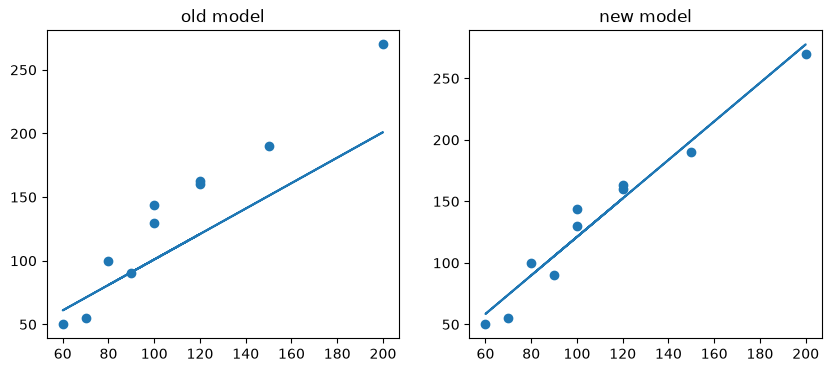

In [60]:
#setting the model with new variables
new_w = 1.5650067895490758
new_b = -35.385698935576805



new_fwb = model(x_train, new_w, new_b)
#drawing the plot

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,4))

ax1.scatter(x_train, y_train)
ax1.plot(x_train, f_wb)
ax1.set_title("old model")

ax2.scatter(x_train, y_train)
ax2.plot(x_train, new_fwb )
ax2.set_title("new model")
plt.show()